# Task Success: Circular vs. Rectangular Hollow Objects

This notebook allows to replicate the same plots in the report, with the possibility to change and add try. 
Each shape has its own CSV fle with the format: `Friction_mu`, `Mass_kg`, `Success`. The same analysis is applied to both, and the charts share the same axes so they can be compared directly.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

CSV_FILES = {
    'Rectangular hollow': 'data_rectangular.csv',
    'Circular hollow':    'data_circular.csv',
}

material_map = {
    0.20: 'Glass (0.2)',
    0.25: 'Metal (0.25)',
    0.30: 'Copper (0.3)',
    0.40: 'Plastic (0.4)',
    0.45: 'Ceramic (0.45)',
    0.50: 'Wood (0.5)',
    0.60: 'Cardboard (0.6)',
    0.90: 'Rubber (0.9)'
}

bins = [0, 0.5, 1.0, float('inf')]
labels = ['0 - 0.5 kg', '0.5 - 1.0 kg', '> 1.0 kg']

## Helper functions

In [8]:
def build_pivot(csv_path):
    """Load a CSV and return success rate (%) per material (rows) and mass group (columns)."""
    df = pd.read_csv(csv_path)
    df['Friction_mu'] = df['Friction_mu'].round(2)
    df['Mass_Group'] = pd.cut(df['Mass_kg'], bins=bins, labels=labels, right=False)

    rates = (
        df.groupby(['Friction_mu', 'Mass_Group'], observed=False)['Success']
          .mean()
          .reset_index()
    )
    rates['Success_Percentage'] = rates['Success'] * 100
    return rates.pivot(index='Friction_mu', columns='Mass_Group', values='Success_Percentage')


def plot_grouped_bar(pivot_df, title, ax=None, show_legend=True):
    """Grouped bar chart with percentage labels. Draws on `ax` if given."""
    pivot_df = pivot_df.copy()
    pivot_df.index = [material_map.get(v, str(v)) for v in pivot_df.index]

    standalone = ax is None
    if standalone:
        fig, ax = plt.subplots(figsize=(12, 7))

    pivot_df.plot(kind='bar', width=0.8, edgecolor='black', ax=ax, legend=show_legend)

    ax.set_title(title, fontsize=14, pad=15)
    ax.set_xlabel(r'Material (Friction $\mu$)', fontsize=12)
    ax.set_ylabel('Success Rate (%)', fontsize=12)
    ax.set_ylim(0, 115)
    ax.tick_params(axis='x', rotation=45)
    for lbl in ax.get_xticklabels():
        lbl.set_ha('right')
    if show_legend:
        ax.legend(title='Mass Group', title_fontsize='11', fontsize='10')

    for p in ax.patches:
        h = p.get_height()
        if pd.notna(h):
            ax.annotate(f'{h:.0f}%',
                        (p.get_x() + p.get_width() / 2., h),
                        ha='center', va='bottom',
                        xytext=(0, 5), textcoords='offset points',
                        fontsize=8, fontweight='bold')

    if standalone:
        plt.tight_layout()
        plt.show()

## Load datasets

In [9]:
pivots = {name: build_pivot(path) for name, path in CSV_FILES.items()}

# Make sure both pivots show the same materials, even if one CSV lacks some
all_materials = sorted(set().union(*[p.index for p in pivots.values()]))
pivots = {name: p.reindex(all_materials) for name, p in pivots.items()}

for name, p in pivots.items():
    print(name)
    display(p.round(1))

Rectangular hollow


Mass_Group,0 - 0.5 kg,0.5 - 1.0 kg,> 1.0 kg
Friction_mu,,,
0.20,100.0,100.0,71.4
0.25,100.0,100.0,66.7
0.30,100.0,33.3,100.0
0.40,100.0,100.0,62.5
0.45,100.0,66.7,85.7
0.50,100.0,100.0,81.8
0.60,100.0,100.0,50.0
0.90,100.0,0.0,80.0


Circular hollow


Mass_Group,0 - 0.5 kg,0.5 - 1.0 kg,> 1.0 kg
Friction_mu,,,
0.20,100.0,0.0,0.0
0.25,100.0,100.0,NaN
0.30,100.0,66.7,0.0
0.40,100.0,66.7,100.0
0.45,100.0,83.3,20.0
0.50,100.0,100.0,40.0
0.60,100.0,25.0,0.0
0.90,100.0,40.0,100.0


## Comparison of the two histograms

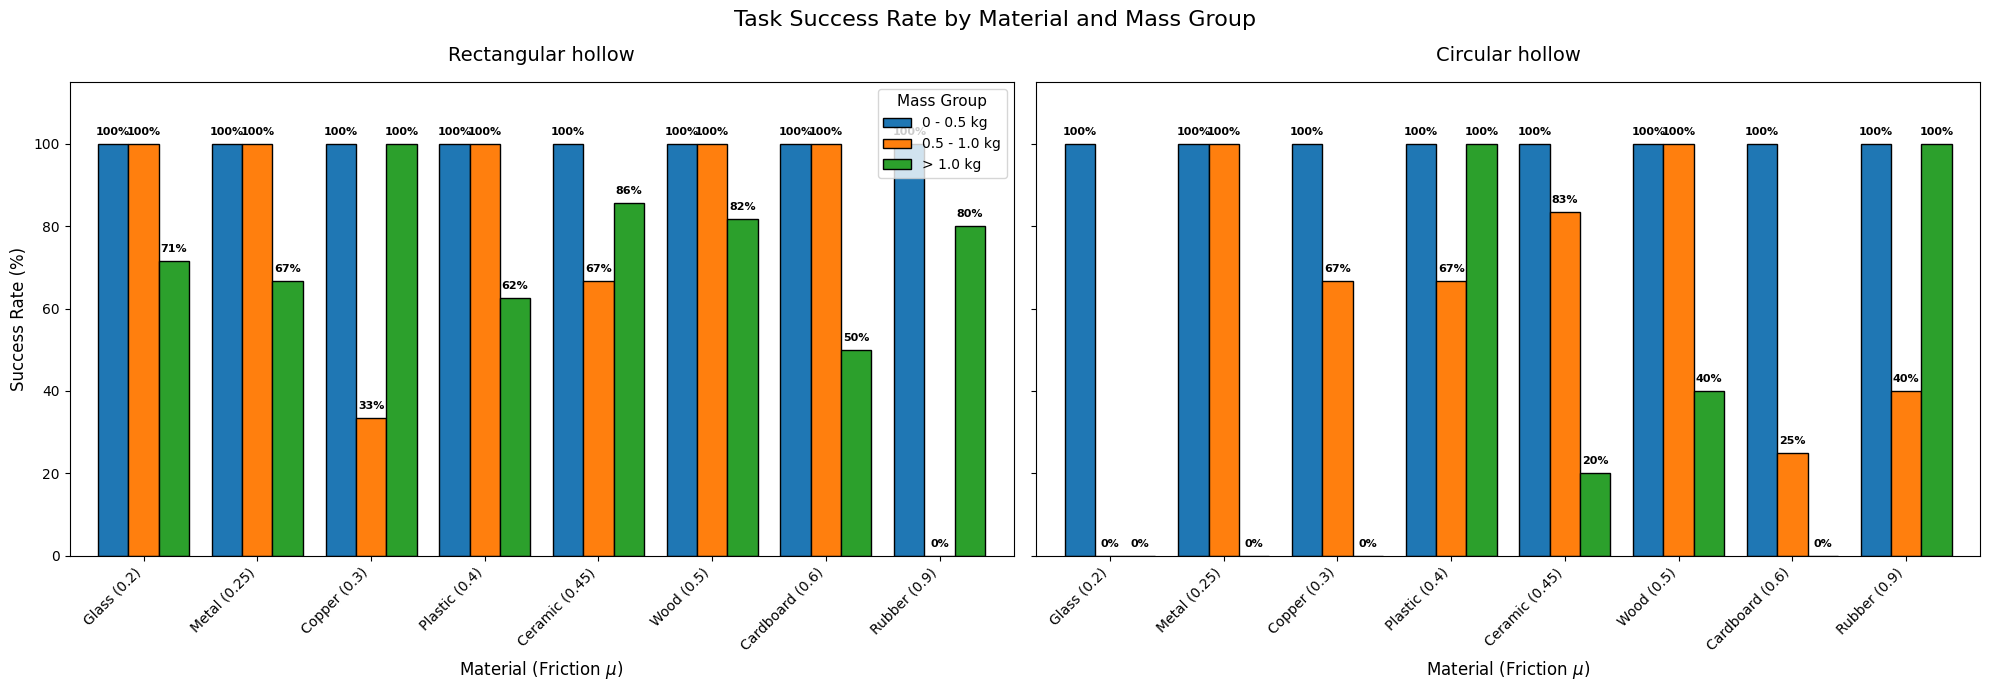

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(20, 7), sharey=True)

for ax, (name, p) in zip(axes, pivots.items()):
    plot_grouped_bar(p, f'{name}', ax=ax, show_legend=(ax is axes[0]))

axes[1].set_ylabel('')
fig.suptitle('Task Success Rate by Material and Mass Group', fontsize=16)
plt.tight_layout()
plt.show()